# 20 — Are our chances honest? Calibration of the Most Improved race

**In brief**
- **Question:** Are the race's chances honest: do players given 20% win about one time in five?
- **Answer:** Yes, almost everywhere, so no correction is applied. The exception is a big early favourite: of 19 players given 25% or more in the first month, only 3 won. So the live race flags any chance above 25% before day 45.
- **Decisions** ([decision log](../../docs/DECISIONS.md)): D40.
- **Where it fits:** Checks the live race (12).
- **Dated:** findings written 10 November 2026; re-run and updated on 12 November 2026 with the live race's current inputs (D41, D42).

**In detail.** When the live race gives a player a 20% chance, do players given 20% win about one time in five? Earlier we suspected the model was **too sure of its early leaders**: day-19 leaders averaged a 19% chance but only 4 of 26 won (notebook 18). This notebook tests that properly, and fixes it if needed.

**The candidate fix: temperature scaling.** The model's chance for player *i* is

$$p_i = \frac{e^{s_i}}{\sum_j e^{s_j}}$$

where $s_i$ is his score. Dividing every score by a temperature $T$ gives $p_i = e^{s_i/T} / \sum_j e^{s_j/T}$:
- $T > 1$ spreads the chances out, which is the fix for overconfidence.
- $T < 1$ sharpens them.
- **The order of the players never changes;** only how sure the model is.

**How it is tested:**
- **Out-of-sample chances throughout.** Each season's chances come from a model that never saw that season (leave-one-out), with the live race's inputs as of 12 November (D38, D39, D41, D42). Seasons 2000-01 → 2025-26, at ten points from day 2 to the end of the season.
- **The temperature is checked the same way.** It is learned without the season it is applied to (a nested test), so the check cannot flatter itself.

Award votes are used only to mark the predictions.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn import mip_history as MH
from unicorn.allstars import add_prior_allstar, load_selections
from unicorn.calibration import fit_temperature, scores, softmax_T
from unicorn.hot_start import add_stale
from unicorn.mip import ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, apply_style

warnings.filterwarnings("ignore")
apply_style()
g = MH.load_games(); info = MH.player_info(); votes, winners = MH.voting(g); sel = load_selections()
from unicorn.mip_eval import LIVE_INPUTS as FEATS, current_frame                 # the live race's inputs
DAYS = [2, 7, 14, 19, 30, 45, 60, 85, 120, None]                                  # None = end of season
label = lambda d: "end" if d is None else f"day {d}"

oos = {}                                  # (day, season) -> (scores, index of the winner)
for day in DAYS:
    f = current_frame(g, info, winners, sel, day=day)
    for s in sorted(f["season"].unique()):
        te = f[f["season"] == s]
        if te["mip"].any():
            m = ChoiceModel(FEATS, MH.L2).fit(f[f["season"] != s])
            oos[(label(day), s)] = (scores(m, te), int(np.flatnonzero(te["mip"].to_numpy())[0]))
print(f"{len({s for _, s in oos})} seasons × {len(DAYS)} points of the season")

26 seasons × 10 points of the season


## 20A — What temperature does the data ask for, and does it help?

In [2]:
rows = []
for day in map(label, DAYS):
    groups = {s: v for (d, s), v in oos.items() if d == day}
    T_all = fit_temperature(list(groups.values()))
    ll_raw = ll_cal = 0.0
    for s, (sc, w) in groups.items():                      # nested: the temperature for season s is learned without s
        T = fit_temperature([v for k, v in groups.items() if k != s])
        ll_raw += np.log(softmax_T(sc, 1.0)[w]); ll_cal += np.log(softmax_T(sc, T)[w])
    rows.append({"point of season": day, "temperature the data asks for": T_all,
                 "fit without (× blind)": np.exp(ll_raw / len(groups) + np.mean([np.log(len(v[0])) for v in groups.values()])),
                 "fit with, nested (× blind)": np.exp(ll_cal / len(groups) + np.mean([np.log(len(v[0])) for v in groups.values()]))})
temps = pd.DataFrame(rows).set_index("point of season")
temps.style.format("{:.2f}")

,temperature the data asks for,fit without (× blind),"fit with, nested (× blind)"
point of season,,,
day 2,1.02,4.34,4.22
day 7,0.99,7.36,7.04
day 14,0.95,10.23,10.01
day 19,0.97,8.54,8.24
day 30,0.95,12.38,12.08
day 45,0.94,16.84,16.41
day 60,0.94,19.85,19.34
day 85,0.92,26.45,26.07
day 120,0.89,32.39,32.29


## 20B — Reliability: do 5% chances win about 5% of the time?

Every candidate's out-of-sample chance is placed in a band. Within each band we compare the **average chance given** with **how often those players actually won**, with a 90% range for the actual share. If the model is honest, the two agree.

In [3]:
from scipy.stats import beta

BANDS = [0, 0.01, 0.03, 0.10, 0.25, 1.0]
BAND_NAMES = ["under 1%", "1–3%", "3–10%", "10–25%", "25%+"]
def reliability(days):
    recs = [(p, j == w) for (d, s), (sc, w) in oos.items() if d in days for j, p in enumerate(softmax_T(sc, 1.0))]
    r = pd.DataFrame(recs, columns=["chance", "won"])
    r["band"] = pd.cut(r["chance"], BANDS, labels=BAND_NAMES, include_lowest=True)
    out = r.groupby("band", observed=True).agg(players=("won", "size"), winners=("won", "sum"), average_chance=("chance", "mean"))
    out["actual share"] = out["winners"] / out["players"]
    out["90% range low"] = beta.ppf(0.05, out["winners"], out["players"] - out["winners"] + 1).round(4)
    out["90% range high"] = beta.ppf(0.95, out["winners"] + 1, out["players"] - out["winners"]).round(4)
    return out

EARLY, LATE = ["day 7", "day 14", "day 19", "day 30"], ["day 60", "day 85", "day 120", "end"]
rel = {"early season (days 7–30)": reliability(EARLY), "later season (day 60 to the end)": reliability(LATE)}
for k, v in rel.items():
    print(k.upper())
    display(v.style.format({"average_chance": "{:.1%}", "actual share": "{:.1%}", "90% range low": "{:.1%}", "90% range high": "{:.1%}"}))

EARLY SEASON (DAYS 7–30)


,players,winners,average_chance,actual share,90% range low,90% range high
band,,,,,,
under 1%,25984,20,0.1%,0.1%,0.1%,0.1%
1–3%,1186,23,1.7%,1.9%,1.3%,2.7%
3–10%,521,34,5.1%,6.5%,4.8%,8.6%
10–25%,121,21,14.8%,17.4%,11.9%,24.0%
25%+,29,4,41.1%,13.8%,4.9%,28.8%


LATER SEASON (DAY 60 TO THE END)


,players,winners,average_chance,actual share,90% range low,90% range high
band,,,,,,
under 1%,28182,4,0.1%,0.0%,0.0%,0.0%
1–3%,754,18,1.7%,2.4%,1.6%,3.5%
3–10%,388,31,5.4%,8.0%,5.8%,10.6%
10–25%,130,19,15.3%,14.6%,9.8%,20.7%
25%+,72,32,46.9%,44.4%,34.4%,54.8%


## 20C — The leaders: too sure, or unlucky?

For each point of the season: the average chance the model gave its #1, against how many #1s actually won. To judge whether the gap is real, we simulate 20,000 alternative histories in which every leader wins with exactly the chance the model gave him. The share of those histories with **as few leader wins as actually happened** is the chance that luck alone explains the gap.

In [4]:
rng = np.random.default_rng(0)
lrows = []
for day in map(label, DAYS):
    lead = [(softmax_T(sc, 1.0).max(), int(np.argmax(sc)) == w) for (d, s), (sc, w) in oos.items() if d == day]
    p = np.array([a for a, _ in lead]); won = int(sum(b for _, b in lead))
    sims = (rng.random((20000, len(p))) < p).sum(axis=1)
    lrows.append({"point of season": day, "seasons": len(p), "leader's average chance": p.mean(), "leader wins expected": p.sum(),
                  "leader wins actual": won, "chance luck alone gives this few": (sims <= won).mean()})
leaders = pd.DataFrame(lrows).set_index("point of season")
leaders.style.format({"leader's average chance": "{:.0%}", "leader wins expected": "{:.1f}", "chance luck alone gives this few": "{:.0%}"})

,seasons,leader's average chance,leader wins expected,leader wins actual,chance luck alone gives this few
point of season,,,,,
day 2,25,16%,4.1,4,61%
day 7,25,22%,5.5,4,31%
day 14,25,22%,5.4,5,53%
day 19,26,19%,4.9,4,44%
day 30,26,25%,6.5,6,52%
day 45,26,28%,7.3,5,20%
day 60,26,34%,8.8,9,64%
day 85,26,38%,9.8,9,44%
day 120,26,39%,10.2,10,55%


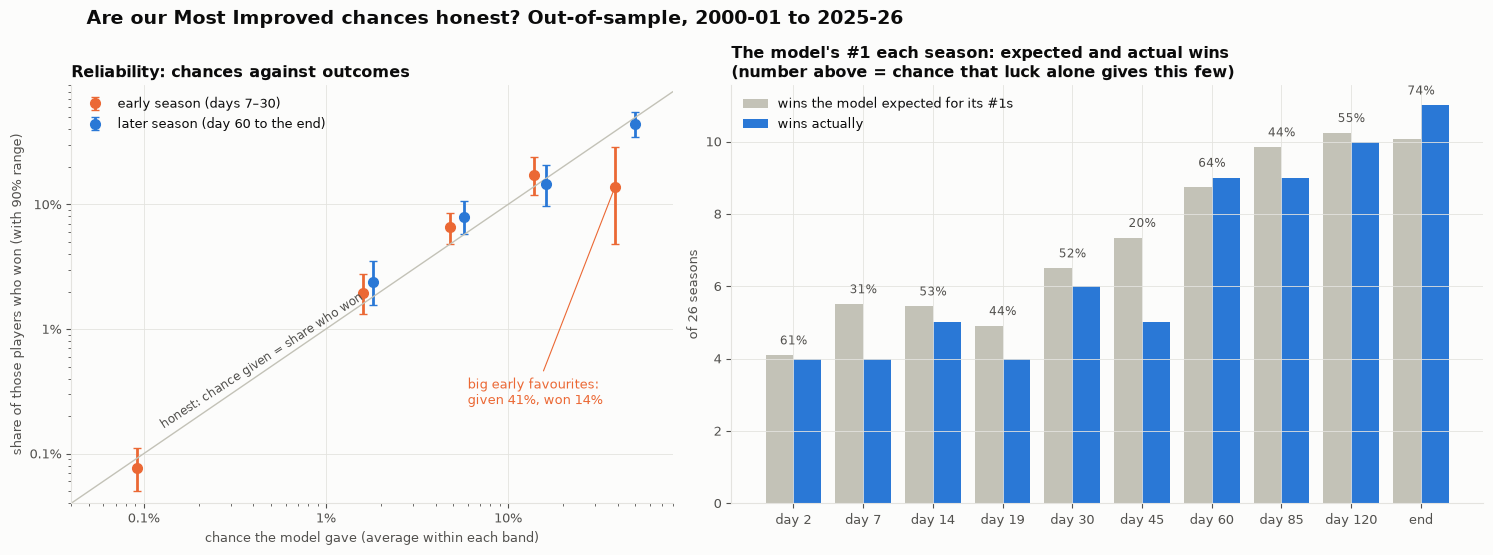

In [5]:
# chart: reliability (early and later season) and the leaders' record
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 1.25]})
for (name, r), col, off in zip(rel.items(), [ORANGE, BLUE], [-0.06, 0.06]):
    x = r["average_chance"].to_numpy(); y = r["actual share"].to_numpy()
    a1.errorbar(x * (1 + off), y, yerr=[np.clip(y - r["90% range low"], 0, None), np.clip(r["90% range high"] - y, 0, None)], fmt="o", color=col,
                capsize=3, markersize=7, label=name)
lim = (0.0004, 0.8)
a1.plot(lim, lim, color=MUTED, linewidth=1); a1.text(0.0012, 0.0016, "honest: chance given = share who won", color=INK2, fontsize=8.5, rotation=33)
a1.set_xscale("log"); a1.set_yscale("log"); a1.set_xlim(*lim); a1.set_ylim(0.0004, 0.9)
ef = rel["early season (days 7–30)"].loc["25%+"]
a1.annotate(f"big early favourites:\ngiven {ef['average_chance']:.0%}, won {ef['actual share']:.0%}", (ef["average_chance"] * 0.94, ef["actual share"]), xytext=(0.06, 0.0025), textcoords="data", fontsize=9, color=ORANGE, arrowprops=dict(arrowstyle="-", color=ORANGE, linewidth=0.8))
fmt = lambda v, _: f"{v:.0%}" if v >= 0.01 else f"{v:.1%}"
a1.xaxis.set_major_formatter(fmt); a1.yaxis.set_major_formatter(fmt)
a1.set_xlabel("chance the model gave (average within each band)"); a1.set_ylabel("share of those players who won (with 90% range)")
a1.legend(frameon=False, loc="upper left", fontsize=9); a1.set_title("Reliability: chances against outcomes", loc="left", fontsize=11.5)
x = np.arange(len(leaders))
a2.bar(x - 0.2, leaders["leader wins expected"], width=0.4, color=MUTED, label="wins the model expected for its #1s")
a2.bar(x + 0.2, leaders["leader wins actual"], width=0.4, color=BLUE, label="wins actually")
for xi, (_, r) in zip(x, leaders.iterrows()):
    a2.text(xi, max(r["leader wins expected"], r["leader wins actual"]) + 0.3, f"{r['chance luck alone gives this few']:.0%}", ha="center", fontsize=8.5, color=INK2)
a2.set_xticks(x, leaders.index, rotation=0, fontsize=9); a2.set_ylabel("of 26 seasons")
a2.legend(frameon=False, loc="upper left", fontsize=9)
a2.set_title("The model's #1 each season: expected and actual wins\n(number above = chance that luck alone gives this few)", loc="left", fontsize=11.5)
fig.suptitle("Are our Most Improved chances honest? Out-of-sample, 2000-01 to 2025-26", x=0.06, ha="left", fontsize=13.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "20_calibration.png", dpi=150, bbox_inches="tight")

## 20D — The exception: big early favourites

Early in the season (days 7–30), candidates given **25% or more** won far less often than their chances say (20B). The same player appears on several days, so here each is counted once, at his average chance over the days he was above 25%.

In [6]:
fav = []
for day in [7, 14, 19, 30]:
    f = current_frame(g, info, winners, sel, day=day)          # the live race's inputs (shared with cell 1)
    for s in sorted(f["season"].unique()):
        te = f[f["season"] == s]
        if te["mip"].any():
            p = ChoiceModel(FEATS, MH.L2).fit(f[f["season"] != s]).predict_proba(te)
            fav.append(te[p >= 0.25].assign(chance=p[p >= 0.25], day=day)[["season", "player_name", "age", "day", "chance", "mip"]])
fav = pd.concat(fav).groupby(["season", "player_name"]).agg(days=("day", list), average_chance=("chance", "mean"), highest=("chance", "max"),
                                                            won=("mip", "max"), age=("age", "first")).sort_values("highest", ascending=False)
p = fav["average_chance"].to_numpy()
sims = (np.random.default_rng(1).random((20000, len(p))) < p).sum(axis=1)
print(f"{len(fav)} early favourites; the model's chances add up to {p.sum():.1f} expected wins; {int(fav['won'].sum())} won; "
      f"chance that luck alone gives this few: {(sims <= fav['won'].sum()).mean():.1%}")
fav.style.format({"average_chance": "{:.0%}", "highest": "{:.0%}", "age": "{:.0f}"})

19 early favourites; the model's chances add up to 7.5 expected wins; 3 won; chance that luck alone gives this few: 2.1%


,,days,average_chance,highest,won,age
season,player_name,,,,,
2023-24,Cam Thomas,"[7, 14, 19, 30]",56%,66%,False,22
2013-14,Eric Bledsoe,"[7, 19, 30]",51%,64%,False,24
2017-18,Aaron Gordon,[7],59%,59%,False,22
2012-13,James Harden,[7],56%,56%,False,23
2021-22,Ja Morant,[7],49%,49%,True,22
2017-18,Kristaps Porziņģis,"[19, 30]",45%,48%,False,23
2019-20,Luka Dončić,[30],44%,44%,False,21
2023-24,Tyrese Maxey,[19],44%,44%,True,23
2019-20,Malcolm Brogdon,[14],42%,42%,False,27


## 20 findings (re-run 12 November 2026 with the live race's current inputs: the game-score turning point, D41, and already clearly a star, D42)

**1. Our chances are honest almost everywhere.**
- Across 26 seasons and ten points of each season, players given 1–3% won about 2% of the time, 3–10% about 6–8%, and 10–25% about 15–17%.
- Later in the season, even players given 25%+ won about as often as their chances say (47% given, 44% won).

**2. A single correction would make things worse.** The temperature the data asks for is close to 1 at every point of the season (0.86–1.02). Applied honestly (learned without the season it is tested on), it lowers the fit slightly everywhere. So there is nothing for a global correction to fix.

**3. The model's #1 is not systematically too sure.** At every point of the season, the gap between the leader's expected and actual wins is within what luck alone produces 20–74% of the time.

**4. The one real exception: big early favourites.**
- **19 players since 2000-01 were given 25% or more between days 7 and 30.** Together the model expected about 7.5 of them to win. **Only 3 did** (Zach Randolph, Ja Morant, Tyrese Maxey). Luck alone would give this few only about 1 time in 50.
- **Most were young, high-usage scorers whose early jump faded or whose award went to someone else:** Cam Thomas (66% at his peak), Eric Bledsoe, Aaron Gordon, James Harden in 2012-13, Kristaps Porziņģis.
- **Two older ones fit notebook 18's pattern:** Malcolm Brogdon (2019-20) and Jerami Grant (2020-21), both 27.

**5. What it means today.** No one in the 2026-27 race is above 25% (Ty Jerome leads with 12.3% on 11 November). His 26.5% before the lost-season input (D39) was the case this would have caught.

**Options for the exception:**
- **A. Flag it, do not change it (recommended).** When an early-season chance (before day 45) is above 25%, the live race prints a note: big early favourites have won about 1 time in 6. It is honest, simple, and does not invent a correction from 19 cases.
- B. Cap or shrink early chances above 25%. It fixes the number, but the size of the shrink would be fitted to 19 players, which is close to fitting noise.
- C. A two-part correction (a temperature for the leader only). It is more complex, and it is the same 19 cases again.

**Decision (10 November, D40):** option A. No change to the model or to any chance; a note in the live race whenever an early chance exceeds 25%.

*Correction (12 November):* an earlier re-run that day reported 18 early favourites. One cell built its frame with the old points turning point while using the new inputs; it now uses the shared `current_frame`, and the count is 19 again, as on 10 November.